# MovieLens 1M — Exploratory Data Analysis

Raw `::`-separated files in `data/raw/` (no header), parsed by the shared loader
`src/movielens/data.py`. This notebook inspects ratings, movies, and users, then
checks cross-file integrity. No models are trained here.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LogNorm


def repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "src").is_dir() and (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("repository root not found")


sys.path.insert(0, str(repo_root() / "src"))

from movielens.data import (
    extract_release_year,
    explode_genres,
    load_movies,
    load_ratings,
    load_users,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)

In [2]:
ratings = load_ratings()
movies = load_movies()
users = load_users()

## 1. Shapes, dtypes, nulls, duplicates

In [3]:
def overview(name, df):
    print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]} cols")
    print(df.dtypes.to_string())
    print(f"nulls={int(df.isna().sum().sum())}  duplicate_rows={int(df.duplicated().sum())}")
    print()


overview("ratings", ratings)
overview("movies", movies)
overview("users", users)

print("duplicate (user_id, movie_id) ratings:", int(ratings.duplicated(subset=["user_id", "movie_id"]).sum()))
print("duplicate movie_id:", int(movies["movie_id"].duplicated().sum()))
print("duplicate user_id:", int(users["user_id"].duplicated().sum()))

ratings: 1,000,209 rows x 4 cols
user_id      int64
movie_id     int64
rating       int64
timestamp    int64


nulls=0  duplicate_rows=0

movies: 3,883 rows x 3 cols
movie_id             int64
title       string[python]
genres      string[python]
nulls=0  duplicate_rows=0

users: 6,040 rows x 5 cols
user_id                int64
gender              category
age                    int64
occupation             int64
zip_code      string[python]
nulls=0  duplicate_rows=0

duplicate (user_id, movie_id) ratings: 0
duplicate movie_id: 0
duplicate user_id: 0


**Summary.** 1,000,209 ratings over 3,883 movies and 6,040 users. No nulls,
no duplicate rows, no duplicate IDs, and no user re-rates the same movie twice.

## 2. Ratings

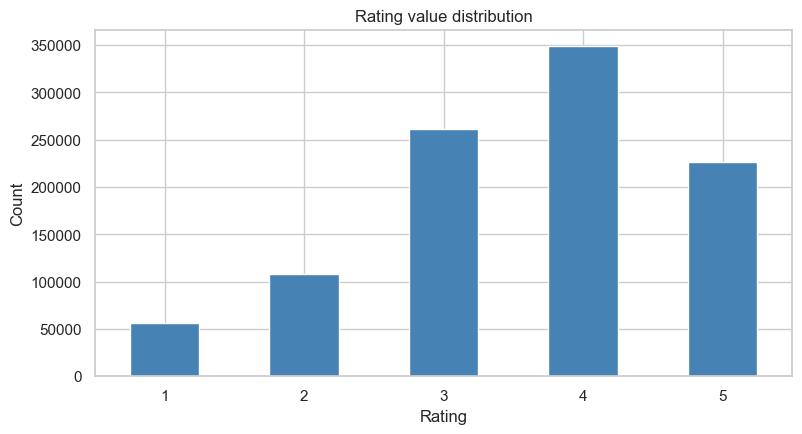

global mean rating: 3.5816
global std: 1.1171
         count
rating        
1        56174
2       107557
3       261197
4       348971
5       226310


In [4]:
rating_counts = ratings["rating"].value_counts().sort_index()
rating_counts.plot(kind="bar", color="steelblue", rot=0)
plt.title("Rating value distribution")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

print("global mean rating:", round(ratings["rating"].mean(), 4))
print("global std:", round(ratings["rating"].std(), 4))
print(rating_counts.to_frame("count").to_string())

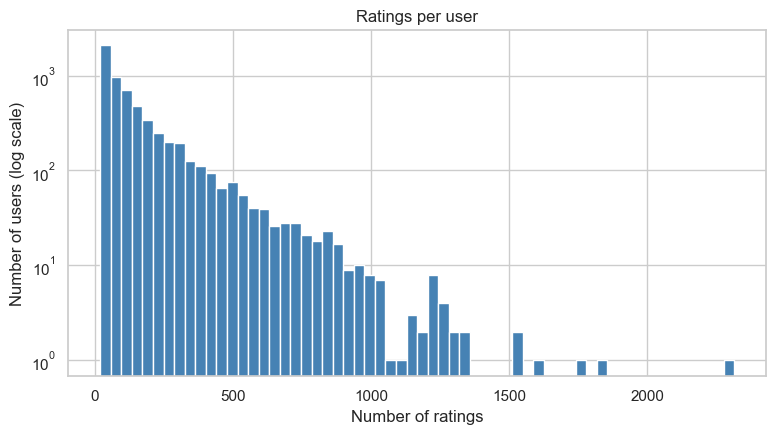

count    6040.00
mean      165.60
std       192.75
min        20.00
25%        44.00
50%        96.00
75%       208.00
max      2314.00
users with <20 ratings: 0


In [5]:
user_counts = ratings["user_id"].value_counts()
user_counts.plot(kind="hist", bins=60, color="steelblue")
plt.yscale("log")
plt.title("Ratings per user")
plt.xlabel("Number of ratings")
plt.ylabel("Number of users (log scale)")
plt.show()

print(user_counts.describe().round(2).to_string())
print("users with <20 ratings:", int((user_counts < 20).sum()))

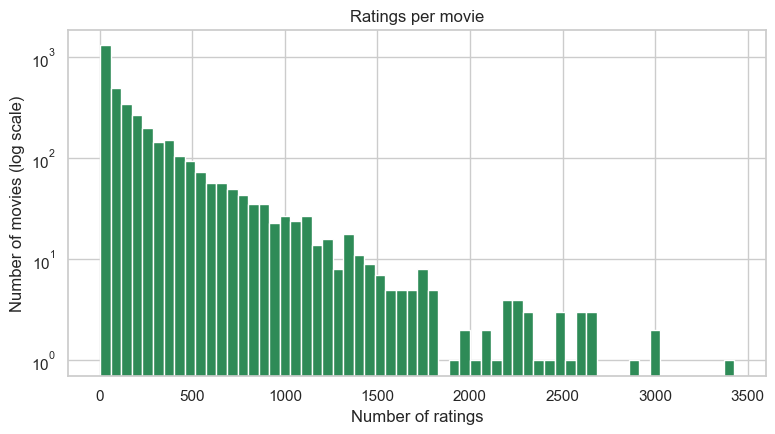

count    3706.00
mean      269.89
std       384.05
min         1.00
25%        33.00
50%       123.50
75%       350.00
max      3428.00


In [6]:
movie_counts = ratings["movie_id"].value_counts()
movie_counts.plot(kind="hist", bins=60, color="seagreen")
plt.yscale("log")
plt.title("Ratings per movie")
plt.xlabel("Number of ratings")
plt.ylabel("Number of movies (log scale)")
plt.show()

print(movie_counts.describe().round(2).to_string())

In [7]:
n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
n_obs = len(ratings)
sparsity = n_obs / (n_users * n_movies)
print(f"users={n_users}  movies_with_ratings={n_movies}  observations={n_obs:,}")
print(f"sparsity={sparsity:.4%}")

users=6040  movies_with_ratings=3706  observations=1,000,209
sparsity=4.4684%


In [8]:
movie_stats = (
    ratings.groupby("movie_id")["rating"]
    .agg(["count", "mean"])
    .join(movies.set_index("movie_id")["title"])
)
print("Top 10 movies by rating count:")
print(movie_stats.sort_values("count", ascending=False).head(10).to_string())
print("\nTop 10 movies by mean rating (min 100 ratings):")
print(movie_stats[movie_stats["count"] >= 100].sort_values("mean", ascending=False).head(10).to_string())
print("\nBottom 10 movies by mean rating (min 100 ratings):")
print(movie_stats[movie_stats["count"] >= 100].sort_values("mean").head(10).to_string())

Top 10 movies by rating count:
          count      mean                                                  title
movie_id                                                                        
2858       3428  4.317386                                 American Beauty (1999)
260        2991  4.453694              Star Wars: Episode IV - A New Hope (1977)
1196       2990  4.292977  Star Wars: Episode V - The Empire Strikes Back (1980)
1210       2883  4.022893      Star Wars: Episode VI - Return of the Jedi (1983)
480        2672  3.763847                                   Jurassic Park (1993)
2028       2653  4.337354                             Saving Private Ryan (1998)
589        2649  4.058513                      Terminator 2: Judgment Day (1991)
2571       2590  4.315830                                     Matrix, The (1999)
1270       2583  3.990321                              Back to the Future (1985)
593        2578  4.351823                       Silence of the Lambs, The (199

min timestamp: 2000-04-25 23:05:32


max timestamp: 2003-02-28 17:49:50


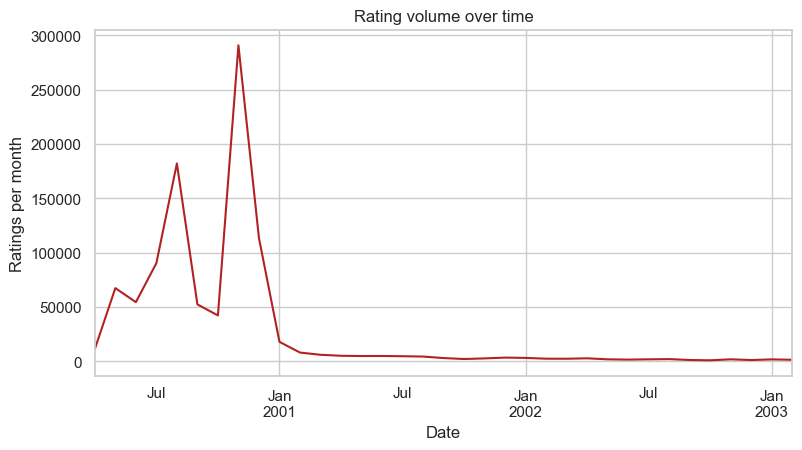

In [9]:
ratings_ts = ratings.copy()
ratings_ts["datetime"] = pd.to_datetime(ratings_ts["timestamp"], unit="s")
print("min timestamp:", ratings_ts["datetime"].min())
print("max timestamp:", ratings_ts["datetime"].max())

monthly = ratings_ts.groupby(ratings_ts["datetime"].dt.to_period("M")).size()
monthly.index = monthly.index.to_timestamp()
monthly.plot(color="firebrick")
plt.title("Rating volume over time")
plt.xlabel("Date")
plt.ylabel("Ratings per month")
plt.show()

**Summary.** Ratings skew positive: mean 3.58, with 4 the modal value (348,971)
and 5 close behind. Every user has at least 20 ratings (the documented floor),
median 96, max 2,314; movie rating counts are heavily long-tailed (median ~124,
max 3,428, many singletons). Only 3,706 of 3,952 movies receive ratings, so
sparsity is 4.47%. Ratings span 2000-04-25 → 2003-02-28 with a large 2000-08
spike (≈291k) and a long decline afterward.

## 3. Movies

genres per movie: min 1 median 1 max 6
distinct genres: 18
genres
Drama          1603
Comedy         1200
Action          503
Thriller        492
Romance         471
Horror          343
Adventure       283
Sci-Fi          276
Children's      251
Crime           211
War             143
Documentary     127
Musical         114
Mystery         106
Animation       105
Fantasy          68
Western          68
Film-Noir        44


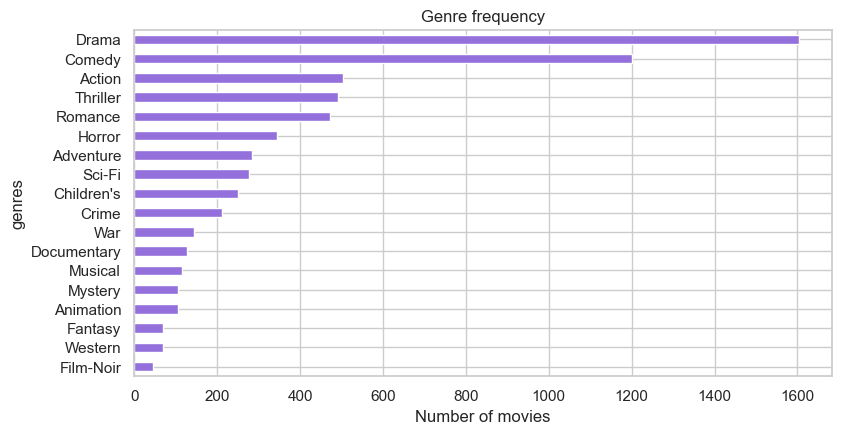

In [10]:
movies = movies.assign(release_year=extract_release_year(movies["title"]))

n_genres = movies["genres"].str.split("|").str.len()
print("genres per movie: min", n_genres.min(), "median", int(n_genres.median()), "max", n_genres.max())

genre_counts = explode_genres(movies)["genres"].value_counts()
print("distinct genres:", genre_counts.size)
print(genre_counts.to_string())

genre_counts.plot(kind="barh", color="mediumpurple")
plt.title("Genre frequency")
plt.xlabel("Number of movies")
plt.gca().invert_yaxis()
plt.show()

release year range: 1919 - 2000
missing year: 0


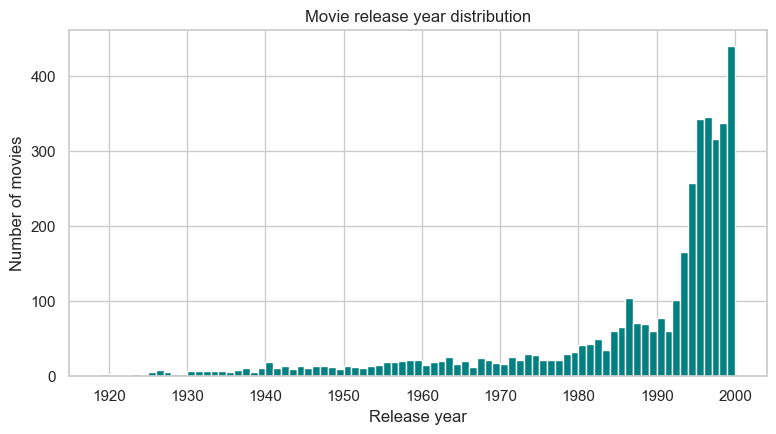

In [11]:
print("release year range:", movies["release_year"].min(), "-", movies["release_year"].max())
print("missing year:", int(movies["release_year"].isna().sum()))

movies["release_year"].plot(kind="hist", bins=range(1919, 2001), color="teal")
plt.title("Movie release year distribution")
plt.xlabel("Release year")
plt.ylabel("Number of movies")
plt.show()

In [12]:
print("duplicate titles:", int(movies["title"].duplicated().sum()))
print("titles missing a year:", int(movies["release_year"].isna().sum()))
print("\nDuplicate-title samples:")
print(movies[movies["title"].duplicated(keep=False)].sort_values("title").head(20).to_string())

duplicate titles: 0
titles missing a year: 0

Duplicate-title samples:
Empty DataFrame
Columns: [movie_id, title, genres, release_year]
Index: []


**Summary.** 18 distinct genres; Drama (1,603) and Comedy (1,200) dominate.
Most movies carry 1–2 genres (max 6). Release years run 1919–2000, peaking in
the 1990s (1995–1999 each >280). Every title embeds a year, but several titles
are duplicated (distinct MovieIDs for the same film), a known hand-entry
artifact.

## 4. Users

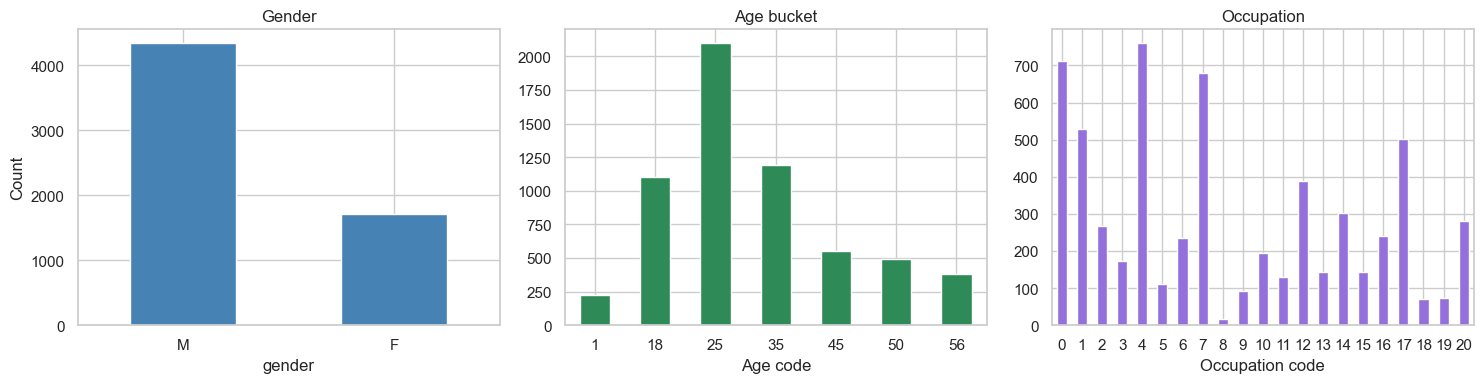

gender:
 gender
M    4331
F    1709

age buckets:
 age
1      222
18    1103
25    2096
35    1193
45     550
50     496
56     380

occupations:
 occupation
0     711
1     528
2     267
3     173
4     759
5     112
6     236
7     679
8      17
9      92
10    195
11    129
12    388
13    142
14    302
15    144
16    241
17    502
18     70
19     72
20    281


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

users["gender"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue", rot=0)
axes[0].set_title("Gender")
axes[0].set_ylabel("Count")

users["age"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="seagreen", rot=0)
axes[1].set_title("Age bucket")
axes[1].set_xlabel("Age code")

users["occupation"].value_counts().sort_index().plot(kind="bar", ax=axes[2], color="mediumpurple", rot=0)
axes[2].set_title("Occupation")
axes[2].set_xlabel("Occupation code")

plt.tight_layout()
plt.show()

print("gender:\n", users["gender"].value_counts().to_string())
print("\nage buckets:\n", users["age"].value_counts().sort_index().to_string())
print("\noccupations:\n", users["occupation"].value_counts().sort_index().to_string())

In [14]:
zip_ok = users["zip_code"].str.fullmatch(r"\d{5}", na=False)
print("5-digit zip codes:", int(zip_ok.sum()), "/", len(users))
print("non-5-digit:", int((~zip_ok).sum()))
print(users.loc[~zip_ok, "zip_code"].value_counts().head(20).to_string())

5-digit zip codes: 5959 / 6040
non-5-digit: 81
zip_code
495321        2
96707-1321    2
98107-2117    1
55405-2546    1
55103-1006    1
37919-4204    1
55337-4056    1
01702-7224    1
20744-6223    1
20110-5616    1
48103-8929    1
53404-1230    1
68144-2410    1
5849574       1
52570-9634    1
93420-2852    1
345567        1
2020010       1
84112-2004    1
23464-3016    1


**Summary.** Users skew male (4,331 M / 1,709 F) and young — the 25–34 bucket
is the largest (2,096), then 35–44 (1,193) and 18–24 (1,103). Occupation is
spread across all 21 codes (college/grad student 759 and "other" 711 lead).
5,959 of 6,040 zip codes are 5-digit; the rest are ZIP+4 or malformed entries.

## 5. Cross-file integrity

In [15]:
valid_users = set(users["user_id"])
valid_movies = set(movies["movie_id"])
rated_movies = set(ratings["movie_id"])
rated_users = set(ratings["user_id"])

print("ratings with unknown user_id:", int((~ratings["user_id"].isin(valid_users)).sum()))
print("ratings with unknown movie_id:", int((~ratings["movie_id"].isin(valid_movies)).sum()))
print("movies with zero ratings:", len(valid_movies - rated_movies))
print("users with zero ratings:", len(valid_users - rated_users))

ratings with unknown user_id: 0
ratings with unknown movie_id: 0
movies with zero ratings: 177
users with zero ratings: 0


**Summary.** Clean referential integrity: every rating references a valid user
and movie. No user is silent, but 177 movies have no ratings — they are
unreachable for collaborative filtering and can be dropped or treated as
cold-start items.

## 6. Rating activity vs. release year

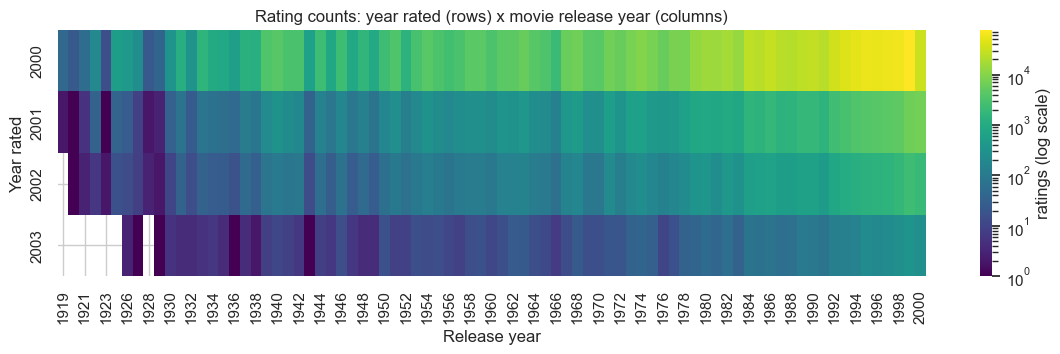

In [16]:
merged = ratings.assign(
    rating_year=pd.to_datetime(ratings["timestamp"], unit="s").dt.year
).merge(movies[["movie_id", "release_year"]], on="movie_id")

pivot = merged.pivot_table(
    index="rating_year", columns="release_year", values="rating", aggfunc="size"
)

plt.figure(figsize=(14, 3.2))
sns.heatmap(pivot, cmap="viridis", norm=LogNorm(), cbar_kws={"label": "ratings (log scale)"})
plt.title("Rating counts: year rated (rows) x movie release year (columns)")
plt.ylabel("Year rated")
plt.xlabel("Release year")
plt.show()

**Summary.** Ratings concentrate on 1990s releases in every rating year, with a
long tail into the 1920s–70s classics. Catalog age (recency at rating time) is a
strong signal, but high-rated older films suggest popularity and quality both
matter.

## 7. Conclusions

- Explicit feedback is dense enough for CF but sparse overall (4.47%); the
  long-tail movie distribution means popularity and item-KNN baselines will
  diverge strongly on ranking metrics.
- Rating scale is heavily positive-skewed; a global mean of 3.58 is a strong
  non-personalized baseline for RMSE/MAE.
- 177 zero-rating movies are a natural cold-start evaluation set.
- Demographic side-information (age, occupation, gender) is nearly complete and
  could augment latent-factor or NCF models.